# 03 — Explainability & Interpretation

The goal is to explain **what the models learned**, **which features matter most**, and **whether that agrees with what is
known about paddy farming in Sri Lanka**.

| Method | Model | Scope |
|---|---|---|
| EBM term importance and shape functions | EBM | global: how each feature changes yield |
| EBM local explanation | EBM | one prediction, split into feature contributions |
| SHAP (TreeExplainer): beeswarm and waterfall | Random Forest | global and local |
| LIME | EBM and Random Forest | local: 3 selected district-seasons |
| Partial Dependence and ICE plots | EBM and Random Forest | global effect of rainfall and irrigation |

The two models are explained with **different methods** and their results are compared. When different methods agree,
the conclusions are more trustworthy.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import partial_dependence

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load_dataset, FEATURES, CATEGORICAL, NUMERIC, TARGET

FIG = ROOT / "reports" / "figures"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

# Plain-English labels for charts
LABEL = {"district": "District", "season": "Season", "year": "Year (trend)", "log_sown_total": "Sown area (log)",
         "sown_share_major": "Share: major irrigation", "sown_share_minor": "Share: minor irrigation",
         "sown_share_rainfed": "Share: rainfed", "rain_total_mm": "Season rainfall (mm)",
         "rain_min_month_mm": "Driest month rain (mm)", "rain_max_month_mm": "Wettest month rain (mm)",
         "rain_cv": "Rainfall unevenness (CV)", "rain_pre_season_mm": "Pre-season rain (mm)",
         "temp_mean_c": "Mean temp (°C)", "temp_max_c": "Max temp (°C)", "temp_min_c": "Min temp (°C)",
         "humidity_pct": "Humidity (%)", "solar_mj_m2_day": "Solar radiation", "wind_m_s": "Wind (m/s)",
         "lag_prev_season": "Previous season yield", "lag_same_season": "Same season last year",
         "roll3_same_season": "3-yr same-season avg"}

df = load_dataset(ROOT)
ebm = joblib.load(ROOT / "models" / "ebm.joblib")
rf = joblib.load(ROOT / "models" / "random_forest.joblib")
trval, test = df[df.year <= 2020].copy(), df[df.year >= 2021].copy()
X_trval, X_te = trval[FEATURES], test[FEATURES]
test["pred_ebm"], test["pred_rf"] = ebm.predict(X_te), rf.predict(X_te)
print(f"train+val {len(trval)} rows | test {len(test)} rows | EBM intercept {ebm.intercept_:,.0f} kg/ha")

train+val 2004 rows | test 240 rows | EBM intercept 3,662 kg/ha


## 1. EBM: global feature importance

EBM's importance for a feature is the **mean absolute contribution** that feature adds to a prediction, in kg/ha, over the
training data. EBM is an additive model, so these contributions are exact. They are not approximations.

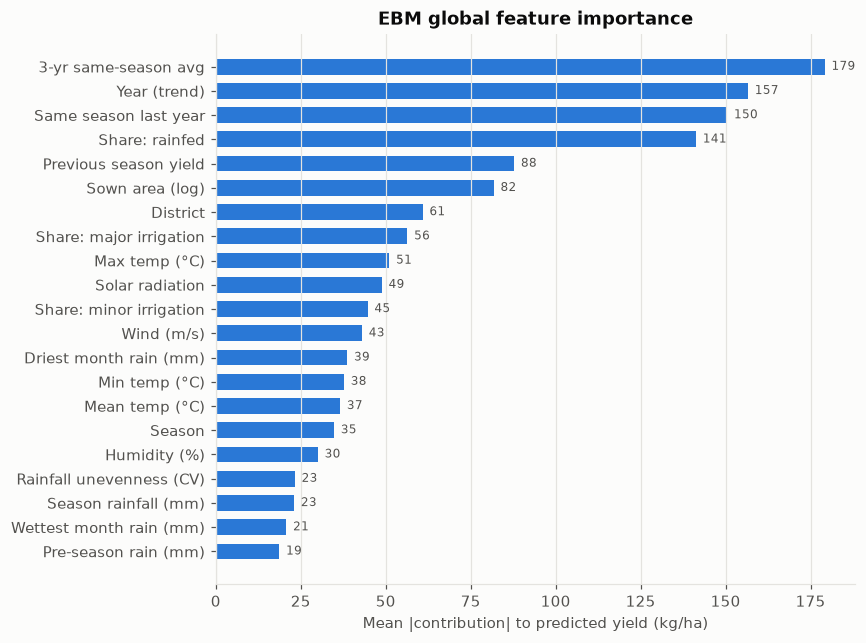

,kg/ha
roll3_same_season,179.2
year,156.6
lag_same_season,150.5
sown_share_rainfed,141.3
lag_prev_season,87.8
log_sown_total,81.8
district,60.9
sown_share_major,56.4
temp_max_c,51.1
solar_mj_m2_day,48.9


In [2]:
imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.barh([LABEL[n] for n in imp.index], imp.values, color=BLUE, height=0.65)
for y, v in enumerate(imp.values):
    ax.text(v + 2, y, f"{v:,.0f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Mean |contribution| to predicted yield (kg/ha)")
ax.set_title("EBM global feature importance")
ax.grid(axis="y", visible=False)
save(fig, "xai_01_ebm_importance")
imp.sort_values(ascending=False).round(1).to_frame("kg/ha")

## 2. EBM shape functions: how each feature changes yield

Each curve is that feature's learned function $f_i(x_i)$. The y-axis is the number of **kg/ha added to or subtracted from**
the average yield. The shaded band shows the uncertainty across EBM's internal bagging. Tick marks along the x-axis show where
the data actually lies. The curve is unreliable where there is little data.

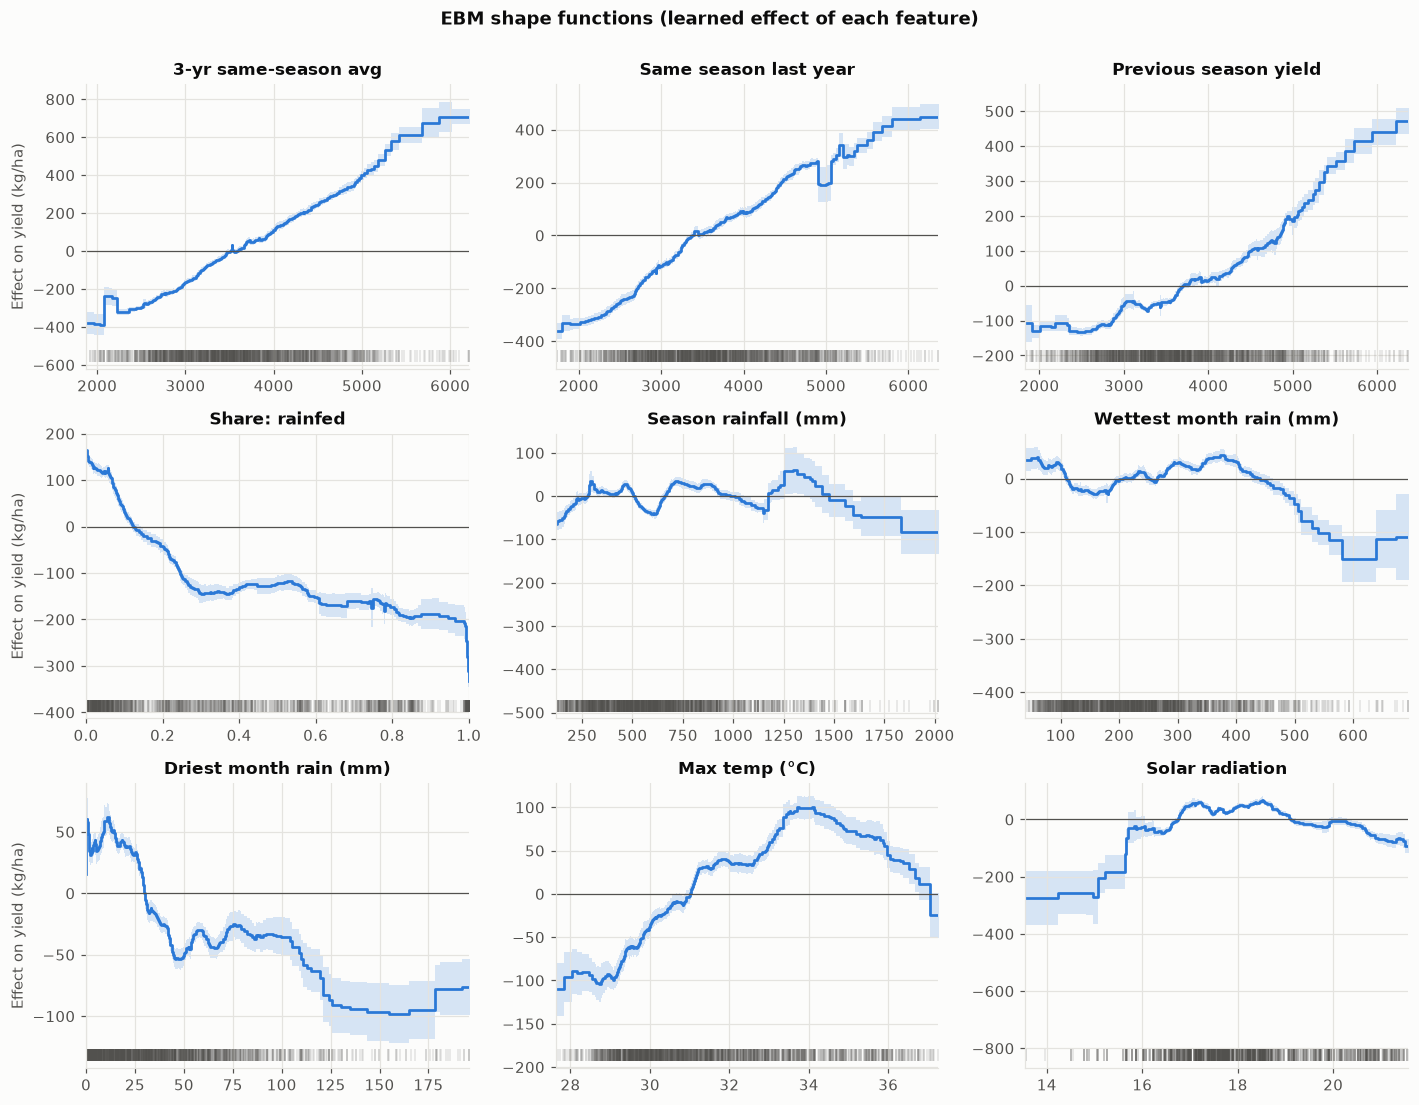

In [3]:
g = ebm.explain_global()

def shape(feature):
    d = g.data(ebm.term_names_.index(feature))
    edges = np.asarray(d["names"], dtype=float)
    return edges, np.asarray(d["scores"]), np.asarray(d["lower_bounds"]), np.asarray(d["upper_bounds"])

def plot_shape(ax, feature, xlim=None):
    edges, s, lo, hi = shape(feature)
    x = np.repeat(edges, 2)[1:-1]
    ax.fill_between(x, np.repeat(lo, 2), np.repeat(hi, 2), color=BLUE, alpha=0.18, lw=0)
    ax.plot(x, np.repeat(s, 2), color=BLUE, lw=1.8)
    ax.axhline(0, color=INK2, lw=0.8)
    vals = trval[feature].dropna()
    ax.plot(vals, np.full(len(vals), ax.get_ylim()[0]), "|", color=INK2, alpha=0.15, ms=8)
    if xlim: ax.set_xlim(*xlim)
    else: ax.set_xlim(vals.quantile(0.005), vals.quantile(0.995))
    ax.set_title(LABEL[feature], fontsize=11)

panel = ["roll3_same_season", "lag_same_season", "lag_prev_season", "sown_share_rainfed",
         "rain_total_mm", "rain_max_month_mm", "rain_min_month_mm", "temp_max_c", "solar_mj_m2_day"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, f in zip(axes.flat, panel):
    plot_shape(ax, f)
for ax in axes[:, 0]: ax.set_ylabel("Effect on yield (kg/ha)")
fig.suptitle("EBM shape functions (learned effect of each feature)", fontweight="bold", color=INK, y=1.0)
fig.tight_layout()
save(fig, "xai_02_ebm_shape_functions")

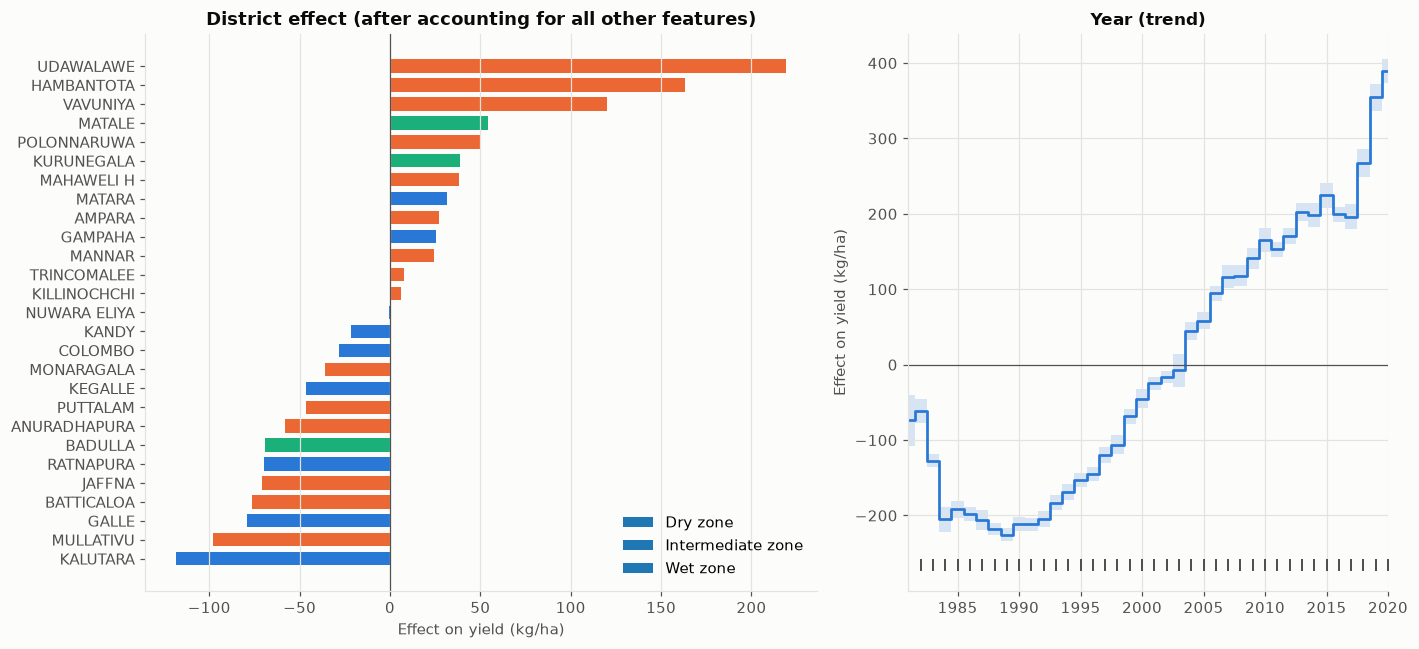

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.4, 1]})
d = g.data(ebm.term_names_.index("district"))
dist = pd.Series(d["scores"], index=d["names"]).sort_values()
zone_color = {"Dry": ORANGE, "Intermediate": AQUA, "Wet": BLUE}
from features import ZONE_OF
axes[0].barh(dist.index, dist.values, color=[zone_color[ZONE_OF[n]] for n in dist.index], height=0.7)
axes[0].axvline(0, color=INK2, lw=0.8)
axes[0].set_title("District effect (after accounting for all other features)")
axes[0].set_xlabel("Effect on yield (kg/ha)"); axes[0].grid(axis="y", visible=False)
for z, c in zone_color.items(): axes[0].barh([], [], color=c, label=f"{z} zone")
axes[0].legend(frameon=False, loc="lower right")
plot_shape(axes[1], "year")
axes[1].set_ylabel("Effect on yield (kg/ha)")
fig.tight_layout()
save(fig, "xai_03_ebm_district_and_year")

## 3. EBM local explanation: the fertilizer-shock season

**Case:** Polonnaruwa, 2021/22 Maha. This is one of the most important rice districts, and its yield fell to **3,103 kg/ha**
from 5,220 the season before. The EBM prediction below is split exactly into the **intercept plus one contribution per feature**.

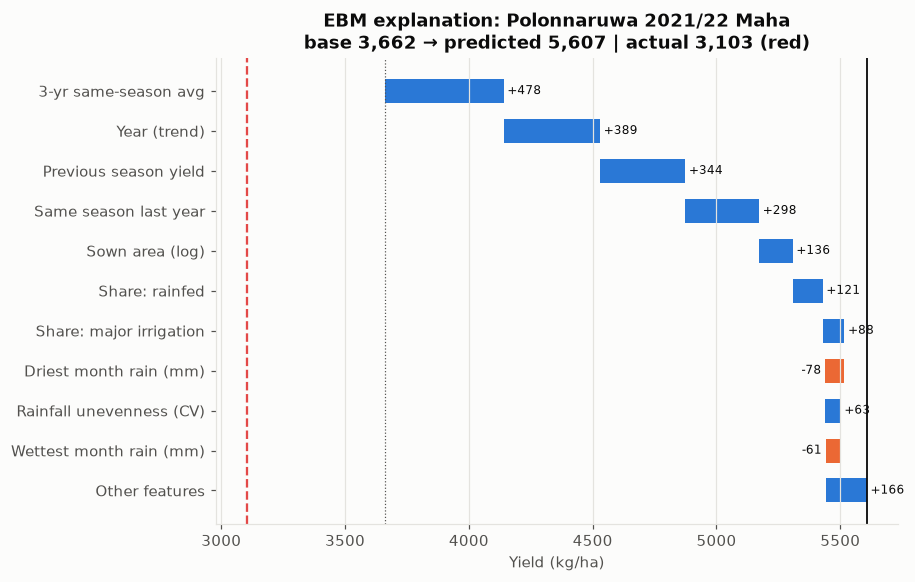

district              POLONNARUWA
season_label         2021/22 Maha
yield_total                3103.0
pred_ebm              5607.064828
pred_rf               5322.743279
lag_prev_season            5441.0
roll3_same_season          5233.0
rain_total_mm             1510.84
Name: 2072, dtype: object

In [5]:
def case(district, label):
    return test[(test.district == district) & (test.season_label == label)].index[0]

def ebm_local(idx, top=10):
    row = test.loc[[idx]]
    loc = ebm.explain_local(row[FEATURES], row[TARGET]).data(0)
    contrib = pd.Series(loc["scores"], index=loc["names"])
    return loc["extra"]["scores"][0], contrib

def plot_waterfall(base, contrib, title, actual, top=10):
    c = contrib.reindex(contrib.abs().sort_values(ascending=False).index)
    shown, rest = c.iloc[:top], c.iloc[top:].sum()
    items = list(shown.items()) + [("Other features", rest)]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    pos = base
    for i, (name, v) in enumerate(items):
        ax.barh(i, v, left=pos, color=BLUE if v >= 0 else ORANGE, height=0.6)
        ax.text(pos + v + (15 if v >= 0 else -15), i, f"{v:+,.0f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK)
        pos += v
    ax.set_yticks(range(len(items)), [LABEL.get(n, n) for n, _ in items]); ax.invert_yaxis()
    ax.axvline(base, color=INK2, lw=0.8, ls=":")
    ax.axvline(pos, color=INK, lw=1.2)
    ax.axvline(actual, color=RED, lw=1.5, ls="--")
    ax.set_xlabel("Yield (kg/ha)")
    ax.set_title(f"{title}\nbase {base:,.0f} → predicted {pos:,.0f} | actual {actual:,.0f} (red)")
    ax.grid(axis="y", visible=False)
    return fig

i_pol = case("POLONNARUWA", "2021/22 Maha")
base, contrib = ebm_local(i_pol)
fig = plot_waterfall(base, contrib, "EBM explanation: Polonnaruwa 2021/22 Maha", test.loc[i_pol, TARGET])
save(fig, "xai_04_ebm_local_polonnaruwa_2022")
test.loc[i_pol, ["district", "season_label", TARGET, "pred_ebm", "pred_rf", "lag_prev_season", "roll3_same_season", "rain_total_mm"]]

## 4. SHAP on the Random Forest (black-box benchmark)

- **TreeExplainer** computes exact SHAP values for tree ensembles.
- The Random Forest pipeline one-hot encodes `district` and `season`, so the SHAP values of the one-hot columns are **summed
  back** into one value per original feature.
- **Mode:** `tree_path_dependent`. The expected value comes from the training data stored in the trees (1981–2020).
- **Explained data:** all 240 test rows from 2021–2025.

**Note on EBM and SHAP:** for an additive model with no interactions, such as our EBM, the SHAP value of a feature equals
its (centred) shape-function contribution. EBM's local explanations in sections 3 and 6 are therefore already exact SHAP values.

In [6]:
prep, forest = rf.named_steps["prep"], rf.named_steps["model"]
names = prep.get_feature_names_out()
Xt = prep.transform(X_te)

# tree_path_dependent: exact SHAP using the training distribution stored in the trees (fast, no background sample)
explainer = shap.TreeExplainer(forest, feature_perturbation="tree_path_dependent")
sv = explainer.shap_values(Xt, check_additivity=False)

def group(col):
    if col.startswith("cat__district_"): return "district"
    if col.startswith("cat__season_"): return "season"
    return col.replace("num__", "")
groups = pd.Series([group(n) for n in names])
sv_grouped = pd.DataFrame(sv, columns=groups).T.groupby(level=0).sum().T[FEATURES]

display_data = X_te.copy()
display_data[["district", "season"]] = np.nan                     # categorical: no colour scale
rf_exp = shap.Explanation(values=sv_grouped.values, base_values=np.full(len(Xt), explainer.expected_value),
                          data=display_data.astype(float).values, feature_names=[LABEL[f] for f in FEATURES])
print("SHAP additivity check (max |base + sum - prediction|):",
      round(np.abs(rf_exp.base_values + rf_exp.values.sum(1) - test.pred_rf.values).max(), 2), "kg/ha")

SHAP additivity check (max |base + sum - prediction|): 0.0 kg/ha


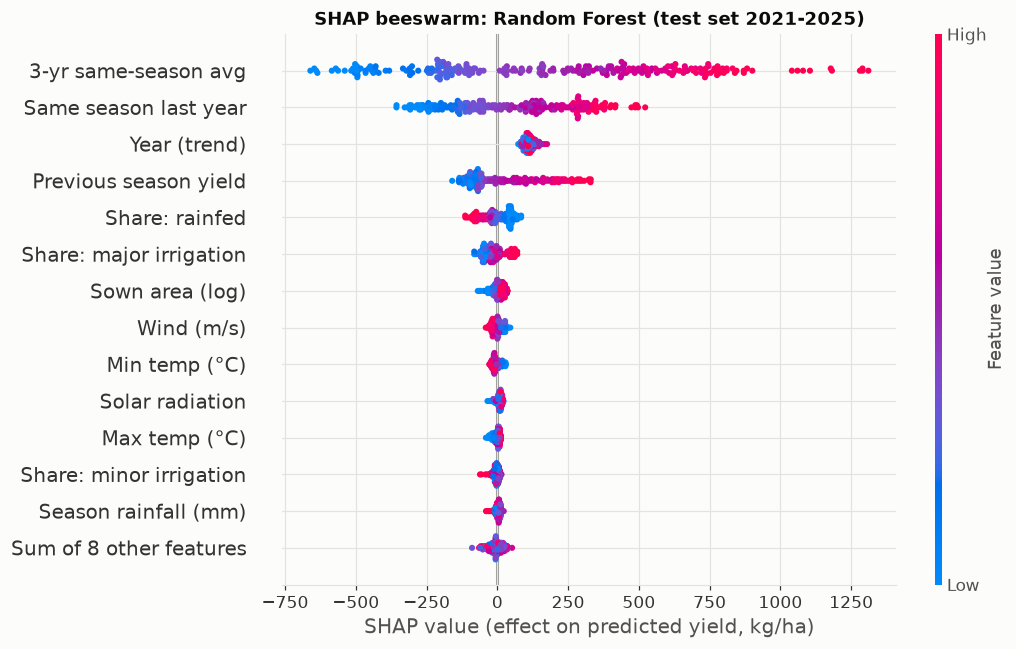

In [7]:
plt.figure()
shap.plots.beeswarm(rf_exp, max_display=14, show=False, plot_size=(9, 6.5))
plt.title("SHAP beeswarm: Random Forest (test set 2021-2025)", fontweight="bold")
plt.xlabel("SHAP value (effect on predicted yield, kg/ha)")
save(plt.gcf(), "xai_05_shap_beeswarm_rf")

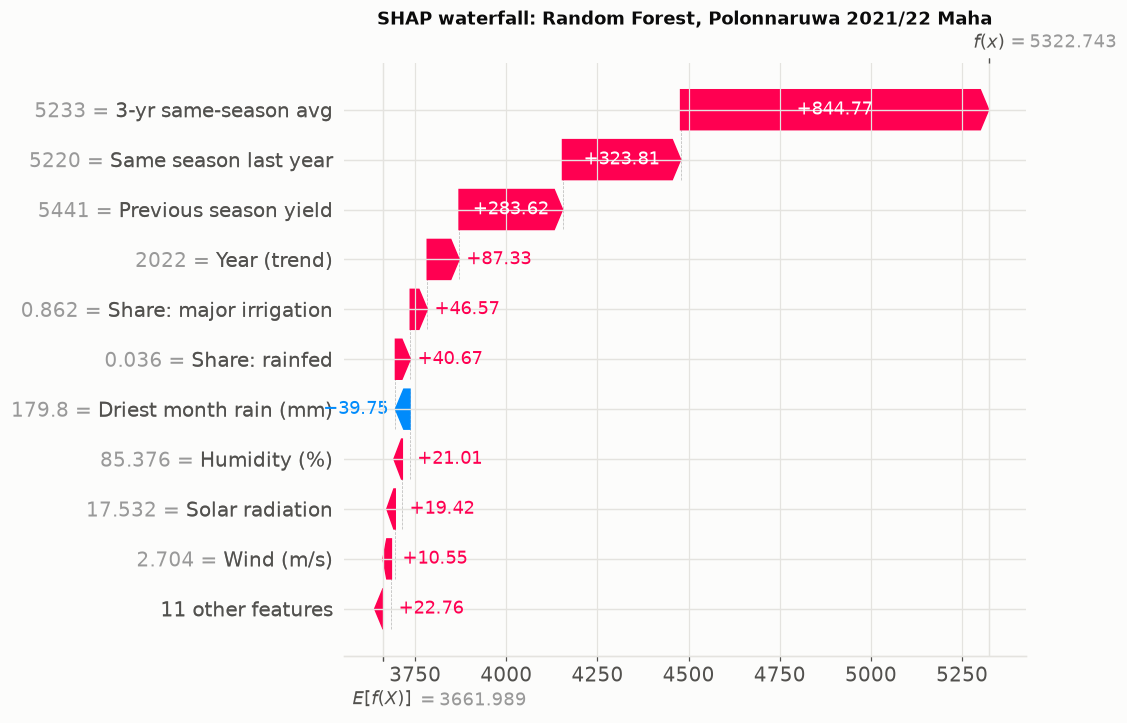

In [8]:
pos = test.index.get_loc(i_pol)
plt.figure()
shap.plots.waterfall(rf_exp[pos], max_display=11, show=False)
plt.title("SHAP waterfall: Random Forest, Polonnaruwa 2021/22 Maha", fontweight="bold")
save(plt.gcf(), "xai_06_shap_waterfall_rf_polonnaruwa_2022")

### Do the two models agree on what matters?

Spearman rank correlation of importances: 0.74


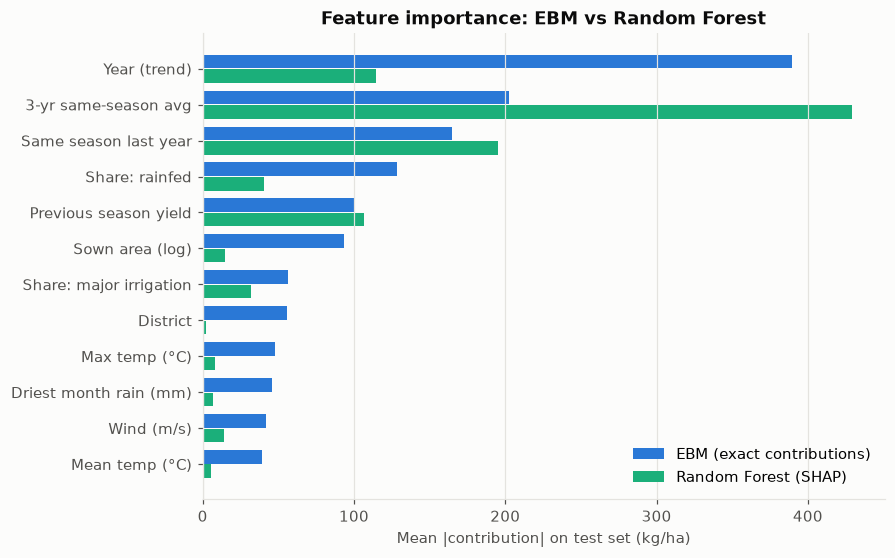

,EBM (exact),RF (SHAP),EBM rank,RF rank
year,389.0,115.0,1,3
roll3_same_season,203.0,429.0,2,1
lag_same_season,165.0,195.0,3,2
sown_share_rainfed,129.0,41.0,4,5
lag_prev_season,100.0,107.0,5,4
log_sown_total,94.0,15.0,6,7
sown_share_major,56.0,32.0,7,6
district,55.0,2.0,8,21
temp_max_c,48.0,8.0,9,11
rain_min_month_mm,46.0,7.0,10,15


In [9]:
shap_imp = sv_grouped.abs().mean()
ebm_test = ebm.explain_local(X_te, test[TARGET])
ebm_contrib = pd.DataFrame([ebm_test.data(i)["scores"] for i in range(len(X_te))], columns=ebm.term_names_)
ebm_imp = ebm_contrib.abs().mean()
agree = pd.DataFrame({"EBM (exact)": ebm_imp, "RF (SHAP)": shap_imp}).loc[FEATURES]
agree["EBM rank"] = agree["EBM (exact)"].rank(ascending=False).astype(int)
agree["RF rank"] = agree["RF (SHAP)"].rank(ascending=False).astype(int)
print("Spearman rank correlation of importances:", round(agree["EBM (exact)"].corr(agree["RF (SHAP)"], method="spearman"), 2))

top = agree.sort_values("EBM (exact)").tail(12)
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["EBM (exact)"], height=0.38, color=BLUE, label="EBM (exact contributions)")
ax.barh(y - 0.2, top["RF (SHAP)"], height=0.38, color=AQUA, label="Random Forest (SHAP)")
ax.set_yticks(y, [LABEL[f] for f in top.index]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean |contribution| on test set (kg/ha)")
ax.set_title("Feature importance: EBM vs Random Forest"); ax.legend(frameon=False, loc="lower right")
save(fig, "xai_07_importance_ebm_vs_rf")
agree.sort_values("EBM rank").round(0)

## 5. LIME: three selected cases

LIME explains one prediction by sampling **perturbed copies** of that row and fitting a small **local linear model** to the
model's responses.
- `district` and `season` are treated as categorical features.
- Missing values are filled with the median, because LIME cannot sample them.
- Each explanation shows the **top 8 feature conditions** and their local weight in kg/ha.

| Case | Why it was chosen |
|---|---|
| Polonnaruwa, 2021/22 Maha | dry-zone rice bowl, fertilizer-shock season (large error) |
| Anuradhapura, 2023 Yala | dry-zone, irrigated, recovery after the shock (typical good prediction) |
| Galle, 2024/25 Maha | wet-zone, mostly rainfed, low-yield district |

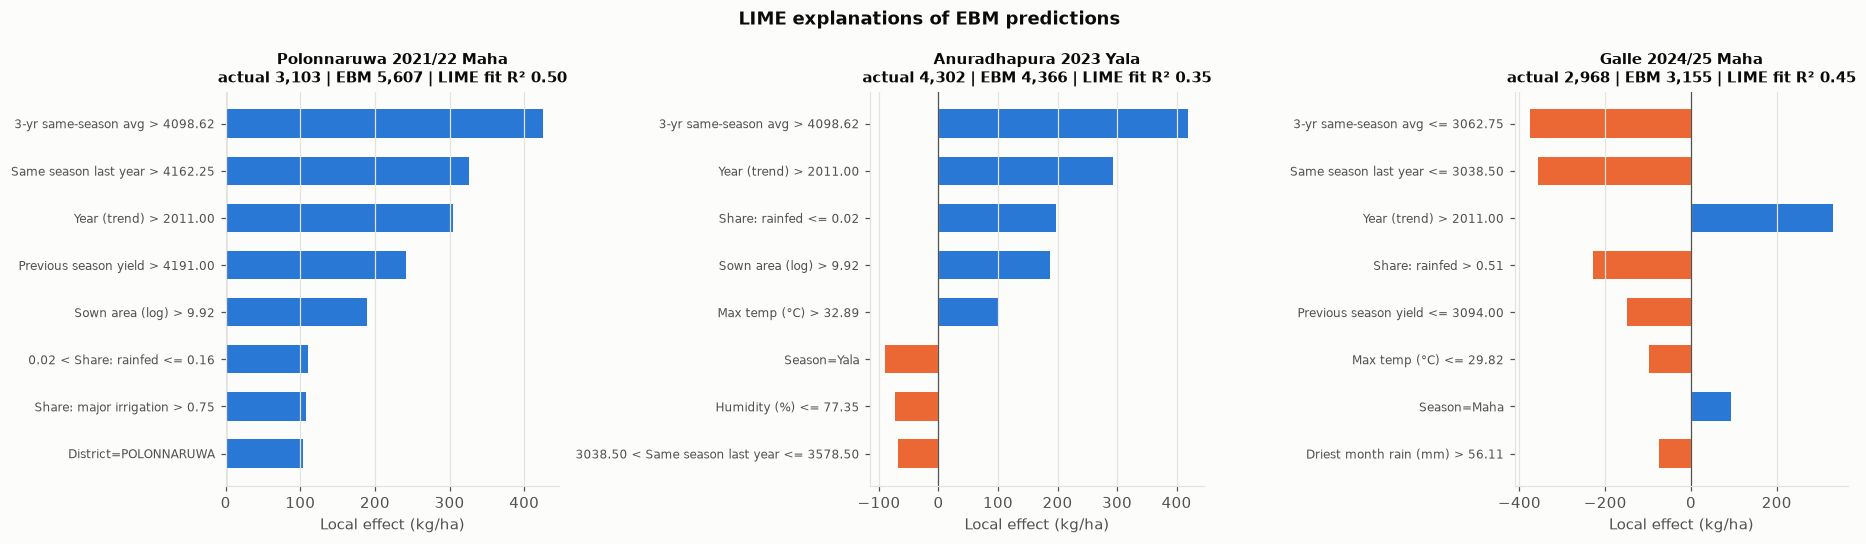


 POLONNARUWA 2021/22 Maha
3-yr same-season avg > 4098.62     425.0
Same season last year > 4162.25    326.0
Year (trend) > 2011.00             305.0
Previous season yield > 4191.00    242.0
Sown area (log) > 9.92             189.0
0.02 < Share: rainfed <= 0.16      110.0
Share: major irrigation > 0.75     108.0
District=POLONNARUWA               103.0

 ANURADHAPURA 2023 Yala
3-yr same-season avg > 4098.62                420.0
Year (trend) > 2011.00                        292.0
Share: rainfed <= 0.02                        198.0
Sown area (log) > 9.92                        188.0
Max temp (°C) > 32.89                         101.0
Season=Yala                                   -89.0
Humidity (%) <= 77.35                         -73.0
3038.50 < Same season last year <= 3578.50    -67.0

 GALLE 2024/25 Maha
3-yr same-season avg <= 3062.75    -376.0
Same season last year <= 3038.50   -358.0
Year (trend) > 2011.00              331.0
Share: rainfed > 0.51              -227.0
Previous season

In [10]:
cat_maps = {c: sorted(df[c].unique()) for c in CATEGORICAL}
medians = X_trval[NUMERIC].median()

def encode(X):
    E = X.copy()
    for c in CATEGORICAL: E[c] = E[c].map({v: i for i, v in enumerate(cat_maps[c])})
    return E.fillna(medians).astype(float).values

def decode(A):
    D = pd.DataFrame(A, columns=FEATURES)
    for c in CATEGORICAL: D[c] = [cat_maps[c][int(round(v))] for v in D[c]]
    for c in NUMERIC: D[c] = D[c].astype(float)
    return D

lime_exp = LimeTabularExplainer(encode(X_trval), feature_names=[LABEL[f] for f in FEATURES], mode="regression",
                                categorical_features=[0, 1], categorical_names={0: cat_maps["district"], 1: cat_maps["season"]},
                                discretize_continuous=True, random_state=42)

cases = [("POLONNARUWA", "2021/22 Maha"), ("ANURADHAPURA", "2023 Yala"), ("GALLE", "2024/25 Maha")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
lime_tables = {}
for ax, (dname, lab) in zip(axes, cases):
    idx = case(dname, lab)
    x = encode(test.loc[[idx], FEATURES])[0]
    e = lime_exp.explain_instance(x, lambda A: ebm.predict(decode(A)), num_features=8, num_samples=3000)
    items = e.as_list()[::-1]
    ax.barh([n for n, _ in items], [v for _, v in items], color=[BLUE if v >= 0 else ORANGE for _, v in items], height=0.6)
    ax.axvline(0, color=INK2, lw=0.8); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    r = test.loc[idx]
    ax.set_title(f"{dname.title()} {lab}\nactual {r[TARGET]:,.0f} | EBM {r.pred_ebm:,.0f} | LIME fit R² {e.score:.2f}", fontsize=10)
    ax.set_xlabel("Local effect (kg/ha)")
    lime_tables[f"{dname} {lab}"] = pd.Series(dict(e.as_list())).round(0)
fig.suptitle("LIME explanations of EBM predictions", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "xai_08_lime_three_cases")
for k, v in lime_tables.items(): print("\n", k); print(v.to_string())

### LIME for the same cases on the Random Forest
This checks whether the black-box model reasons in the same way as EBM.

In [11]:
rows = []
for dname, lab in cases:
    idx = case(dname, lab)
    x = encode(test.loc[[idx], FEATURES])[0]
    e = lime_exp.explain_instance(x, lambda A: rf.predict(decode(A)), num_features=5, num_samples=3000)
    rows.append({"case": f"{dname.title()} {lab}", "RF pred": round(test.loc[idx, "pred_rf"]),
                 "top-5 LIME conditions (RF)": "; ".join(f"{n} ({v:+.0f})" for n, v in e.as_list())})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows)

,case,RF pred,top-5 LIME conditions (RF)
0,Polonnaruwa 2021/22 Maha,5323,3-yr same-season avg > 4098.62 (+895); Same season last year > 4162.25 (+361); Previous season yield > 4191.00 (+241); Year (trend) > 2011.00 (+87); Share: major irrigation > 0.75 (+54)
1,Anuradhapura 2023 Yala,4320,3-yr same-season avg > 4098.62 (+867); 3038.50 < Same season last year <= 3578.50 (-150); Share: rainfed <= 0.02 (+93); Year (trend) > 2011.00 (+85); Sown area (log) > 9.92 (+43)
2,Galle 2024/25 Maha,2963,3-yr same-season avg <= 3062.75 (-715); Same season last year <= 3038.50 (-290); Previous season yield <= 3094.00 (-105); Share: major irrigation <= 0.18 (-98); Year (trend) > 2011.00 (+80)


## 6. Partial Dependence (PDP) and ICE: rainfall and irrigation

- A **partial dependence plot (PDP)** shows the average predicted yield as one feature is varied while all others are kept at their
  observed values. It is computed on a sample of 400 rows from 1981–2020.
- The **ICE** lines are individual district-seasons, shown thin and grey. Parallel ICE lines mean the effect is similar everywhere.
  Crossing lines would point to interactions.

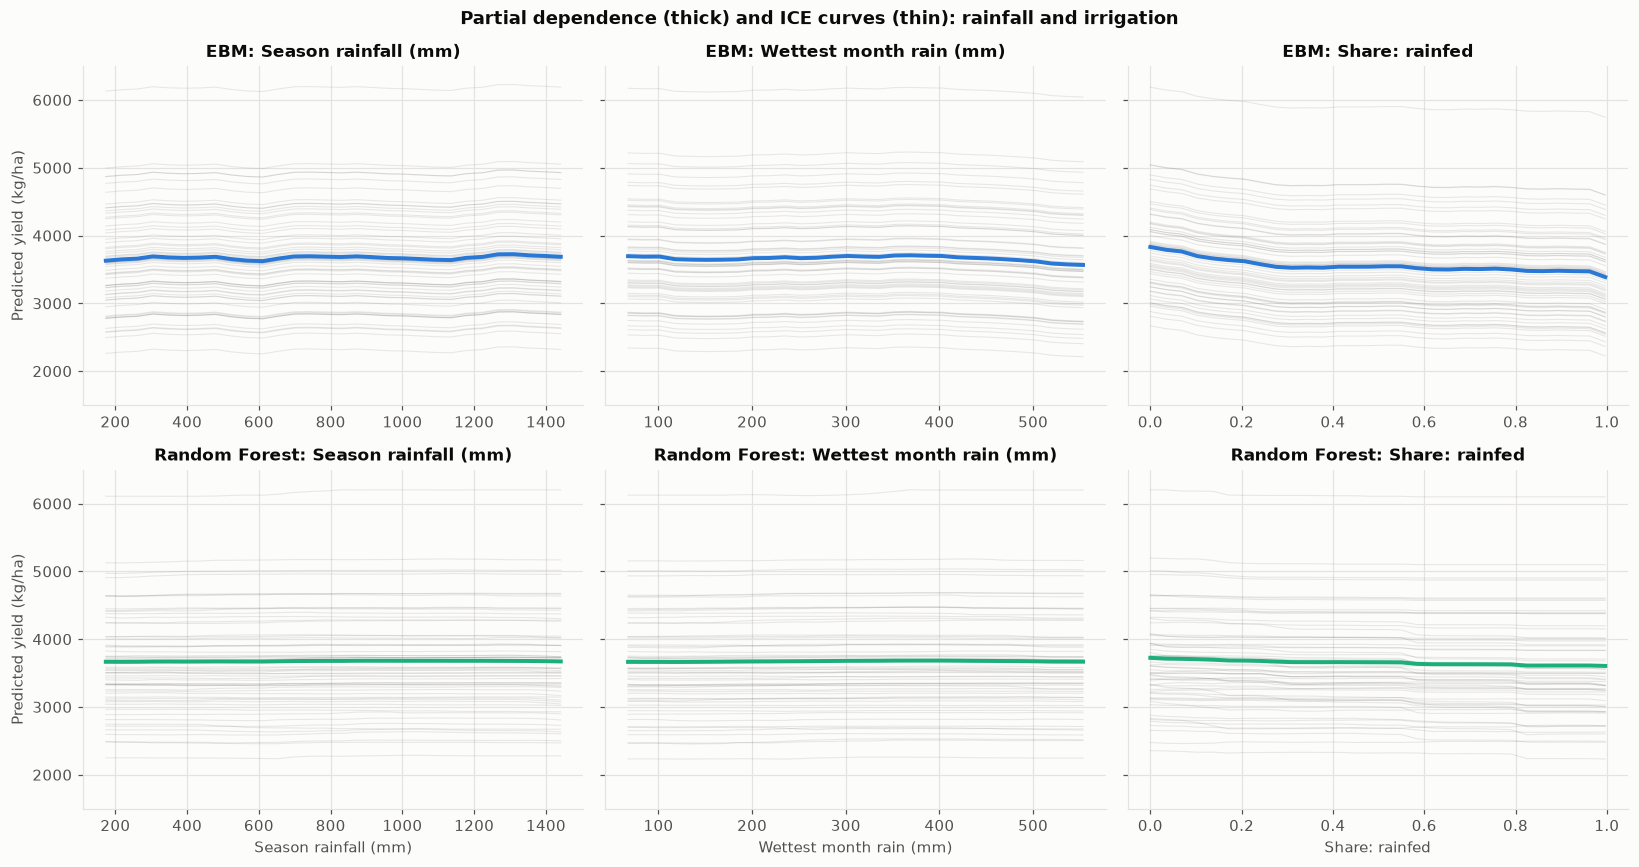

In [12]:
sample = X_trval.sample(400, random_state=1)
pdp_feats = ["rain_total_mm", "rain_max_month_mm", "sown_share_rainfed"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
for col, f in enumerate(pdp_feats):
    grid_vals = np.linspace(*sample[f].quantile([0.02, 0.98]), 30)
    for row, (mname, model, color) in enumerate([("EBM", ebm, BLUE), ("Random Forest", rf, AQUA)]):
        res = partial_dependence(model, sample, [f], kind="both", custom_values={f: grid_vals},
                                 method="brute")
        ax = axes[row, col]
        for line in res["individual"][0][:60]:   # show 60 ICE lines for readability
            ax.plot(grid_vals, line, color=INK2, alpha=0.12, lw=0.7)
        ax.plot(grid_vals, res["average"][0], color=color, lw=2.6, label=f"{mname} PDP")
        ax.set_title(f"{mname}: {LABEL[f]}", fontsize=11)
        ax.set_ylim(1500, 6500)
        if col == 0: ax.set_ylabel("Predicted yield (kg/ha)")
        if row == 1: ax.set_xlabel(LABEL[f])
fig.suptitle("Partial dependence (thick) and ICE curves (thin): rainfall and irrigation", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "xai_09_pdp_ice_rainfall_irrigation")

## 7. Does the model agree with domain knowledge?

Each check below is a claim from Sri Lankan rice agronomy or recent history. It is tested against what the model learned,
using the EBM shape functions, the district effects and the test-set residuals.

In [13]:
def effect_between(feature, lo_q, hi_q):
    edges, s, _, _ = shape(feature)
    centers = (edges[:-1] + edges[1:]) / 2
    vals = trval[feature].dropna()
    lo, hi = vals.quantile(lo_q), vals.quantile(hi_q)
    return float(np.interp(hi, centers, s) - np.interp(lo, centers, s)), lo, hi

checks = []
e, lo, hi = effect_between("sown_share_rainfed", 0.10, 0.90)
checks.append(("More rainfed (non-irrigated) land lowers yield", f"rainfed share {lo:.0%} → {hi:.0%}: {e:+,.0f} kg/ha", e < 0))

dist = pd.Series(g.data(ebm.term_names_.index("district"))["scores"], index=g.data(ebm.term_names_.index("district"))["names"])
zmean = dist.groupby(dist.index.map(ZONE_OF)).mean()
checks.append(("Dry-zone districts yield more than wet-zone (sunshine + irrigation)",
               f"mean district effect: Dry {zmean['Dry']:+,.0f}, Intermediate {zmean['Intermediate']:+,.0f}, Wet {zmean['Wet']:+,.0f}",
               zmean["Dry"] > zmean["Wet"]))

e, lo, hi = effect_between("rain_max_month_mm", 0.50, 0.98)
checks.append(("Extreme rainfall (flood months) is harmful", f"wettest month {lo:,.0f} → {hi:,.0f} mm: {e:+,.0f} kg/ha", e < 0))

e, lo, hi = effect_between("rain_min_month_mm", 0.02, 0.50)
checks.append(("A very dry month (drought) is harmful", f"driest month {lo:,.0f} → {hi:,.0f} mm: {e:+,.0f} kg/ha (positive = more rain helps)", e > 0))

e, lo, hi = effect_between("roll3_same_season", 0.10, 0.90)
checks.append(("Yield is persistent (good districts stay good)", f"3-yr average {lo:,.0f} → {hi:,.0f}: {e:+,.0f} kg/ha", e > 0))

e, lo, hi = effect_between("year", 0.05, 0.95)
checks.append(("Long-run improvement (varieties, inputs)", f"year {lo:.0f} → {hi:.0f}: {e:+,.0f} kg/ha", e > 0))

e, lo, hi = effect_between("solar_mj_m2_day", 0.10, 0.90)
checks.append(("More sunshine raises yield", f"solar {lo:.1f} → {hi:.1f} MJ/m²/day: {e:+,.0f} kg/ha", e > 0))

shock = test[test.fertilizer_shock == 1]
res_shock = (shock[TARGET] - shock.pred_ebm).mean()
res_norm = (test[test.fertilizer_shock == 0][TARGET] - test[test.fertilizer_shock == 0].pred_ebm).mean()
checks.append(("2021 fertilizer ban cut yields (model could not know)",
               f"mean actual − predicted: shock seasons {res_shock:+,.0f}, other test seasons {res_norm:+,.0f} kg/ha", res_shock < -500))

domain = pd.DataFrame(checks, columns=["Domain-knowledge claim", "What the model shows", "Consistent?"])
domain["Consistent?"] = domain["Consistent?"].map({True: "✅ yes", False: "❌ no"})
domain.style.hide(axis="index")

Domain-knowledge claim,What the model shows,Consistent?
More rainfed (non-irrigated) land lowers yield,rainfed share 0% → 82%: -353 kg/ha,✅ yes
Dry-zone districts yield more than wet-zone (sunshine + irrigation),"mean district effect: Dry +18, Intermediate +8, Wet -34",✅ yes
Extreme rainfall (flood months) is harmful,wettest month 224 → 548 mm: -104 kg/ha,✅ yes
A very dry month (drought) is harmful,driest month 0 → 31 mm: -68 kg/ha (positive = more rain helps),❌ no
Yield is persistent (good districts stay good),"3-yr average 2,649 → 4,718: +558 kg/ha",✅ yes
"Long-run improvement (varieties, inputs)",year 1983 → 2018: +394 kg/ha,✅ yes
More sunshine raises yield,solar 16.6 → 20.7 MJ/m²/day: -4 kg/ha,❌ no
2021 fertilizer ban cut yields (model could not know),"mean actual − predicted: shock seasons -1,352, other test seasons -230 kg/ha",✅ yes


## 8. Summary of what the model learned

### Most influential features
- **EBM importance** (mean absolute contribution on the training data):
  1. 3-year same-season average yield (179 kg/ha)
  2. year trend (157)
  3. same season last year (151)
  4. rainfed share (141)
  5. previous season's yield (88)
- **SHAP on the Random Forest** gives almost the same top 5: 3-year average, same season last year, year trend, previous season, rainfed share.
- **LIME** on both models picks the same leading conditions for all three cases.
- The rank correlation between EBM and RF importances is **0.74**. Three different methods applied to two different models
  agree, so the ranking is robust.

**What the model has learned:**
- *"A district-season will yield roughly what it has yielded recently"*. This is persistence, captured by the lags.
- That level is adjusted by:
  - the **long-run improvement trend**
  - **how much of the area is irrigated**
  - smaller **weather** effects, typically ±50–150 kg/ha, compared with ±400–700 kg/ha for the lag features
- The PDP/ICE plots show this clearly. Varying season rainfall moves the average prediction by under 100 kg/ha.
  The ICE lines are nearly parallel, so the effect is similar across districts.

### Domain-knowledge check

| Claim | Result | Evidence |
|---|---|---|
| Irrigated land yields more than rainfed | ✅ | Going from 0% to 82% rainfed: −353 kg/ha. The curve falls steeply between 0 and 30%. |
| Dry-zone districts out-yield the wet zone | ✅ | Mean district effect: Dry +18, Wet −34, on top of the irrigation and lag effects. |
| Flood-level rain is harmful | ✅ | Wettest month above about 450 mm: −100 to −150 kg/ha. This matches the 2010/11 Maha floods. |
| Heat stress above about 35 °C | ✅ | The max-temperature curve peaks near **34 °C** and falls by about 120 kg/ha towards 37 °C. This is consistent with rice heat stress at flowering. |
| Long-run yield improvement | ✅ | Year 1983 → 2018: +394 kg/ha (improved varieties, inputs, irrigation). |
| Yield persistence | ✅ | 3-year average 2,649 → 4,718: +558 kg/ha. |
| More sunshine raises yield | ⚠️ partly | Very cloudy seasons (solar below about 15.5 MJ/m²/day) lose about 250 kg/ha. Above that the curve is flat. |
| A very dry month (drought) is harmful | ❌ | The model learned the **opposite**: more rain in the driest month → −68 kg/ha. |
| 2021 fertilizer ban cut yields | ✅ (not learned) | Mean residual of −1,352 kg/ha in the shock seasons, against −230 in other test seasons. The model expected a normal season. |

### Why the "drought" check fails: confounding
- The districts where even the *driest* month is wet are the **wet-zone, mostly rainfed** districts: Galle, Kalutara, Ratnapura.
  Their yields are low.
- The irrigated **dry-zone** districts often have near-zero rain in their driest month, yet yield the most, because
  irrigation tanks supply the water.
- So `rain_min_month_mm` partly acts as a **proxy for the climate zone**, not for drought stress.
- An additive model with correlated features can split an effect between them in a way that is not causal.
- With district-level, season-total data, the model **cannot separate** drought from irrigation access.
  Farm-level or irrigation-release data would be needed to do that.
- This is a limitation to state in the report.
- It also shows why model explanations must be read with domain knowledge, not taken as causal effects.

### Local explanation: Polonnaruwa 2021/22 Maha
- **Actual yield:** 3,103 kg/ha.
- **Predictions:** EBM 5,607 and RF 5,323.
- **What drove the prediction:** the EBM waterfall, the SHAP waterfall and LIME all show it was pushed **up** by the strong recent
  yields (3-year average 5,233, previous season 5,441), the high-irrigation profile and the year trend.
- **Why it was wrong:** none of these inputs carries the fertilizer ban.
- **What this shows:** the explanations let us see **why** the model was wrong. It reasoned correctly from its inputs, but the cause
  of the loss was outside its feature set. This is the kind of insight a black-box accuracy number cannot provide.

### Implications
- Planners could use the model for **normal-season** yield expectations, about ±490 kg/ha, and for **flagging** districts where weather is unusual.
- It must not be trusted in seasons with **policy or input shocks** such as fertilizer, fuel or seed shortages.
  Expert judgement must override it there.
